# DSA80003: Data Mining
**Group:** 4 

**Members:**

**Submission Date:** 26th November, 2026

### Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotnine
from pathlib import Path
import zipfile
import urllib.request
from pathlib import Path
import pandas as pd

## Data Collection

In [2]:
# 1. Define root path
data_dir = Path("UCI HAR Dataset")
dataset_url = "https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip"

# 2. Check if dataset exists; if not, provide instructions or auto-download
if not data_dir.exists():
    print(f"Dataset folder '{data_dir}' not found locally.")
    print("Attempting to automatically download the UCI HAR dataset...")
    
    try:
        zip_path = Path("uci_har.zip")
        urllib.request.urlretrieve(dataset_url, zip_path)
        
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            zip_ref.extractall(".")
            
        # The UCI zip contains a nested zip or folder structure sometimes, 
        # let's clean up the zip file
        zip_path.unlink()
        print("Dataset downloaded and extracted successfully!")
        
    except Exception as e:
        raise FileNotFoundError(
            f"Could not automatically download the dataset: {e}\n\n"
            f"Please download 'Human Activity Recognition Using Smartphones' manually from:\n"
            f"https://archive.ics.uci.edu/dataset/240/human+activity+recognition+using+smartphones\n"
            f"Extract the 'UCI HAR Dataset' folder into your project root directory."
        )

# 3. Load features safely
features_file = data_dir / "features.txt"
if not features_file.exists():
    raise FileNotFoundError(f"Required file missing: {features_file}. Check your folder structure.")

features_df = pd.read_csv(features_file, sep=r"\s+", header=None, names=["index", "feature_name"])
raw_feature_names = features_df["feature_name"].tolist()

# Make feature names unique by appending a counter to duplicates
seen = {}
feature_names = []
for name in raw_feature_names:
    if name in seen:
        seen[name] += 1
        feature_names.append(f"{name}_{seen[name]}")
    else:
        seen[name] = 0
        feature_names.append(name)

print(f"Successfully loaded {len(feature_names)} unique feature names.")

Successfully loaded 561 unique feature names.


### Split Dataset

In [3]:
import pandas as pd
from pathlib import Path

# 1. Define root path and load features ONCE (since they are shared between train and test)
data_dir = Path("UCI HAR Dataset")

features_df = pd.read_csv(data_dir / "features.txt", sep=r"\s+", header=None, names=["index", "feature_name"])
raw_feature_names = features_df["feature_name"].tolist()

# Make feature names unique by appending a counter to duplicates
seen = {}
feature_names = []
for name in raw_feature_names:
    if name in seen:
        seen[name] += 1
        feature_names.append(f"{name}_{seen[name]}")
    else:
        seen[name] = 0
        feature_names.append(name)


# 2. Create a reusable function for loading any split ('train' or 'test')
def load_har_split(split_name: str, data_dir: Path, feature_names: list) -> pd.DataFrame:
    """
    Loads and combines subject IDs, activity labels, and features 
    for a given dataset split ('train' or 'test').
    """
    split_dir = data_dir / split_name
    
    # Load individual components dynamically based on the split name
    X = pd.read_csv(split_dir / f"X_{split_name}.txt", sep=r"\s+", header=None, names=feature_names)
    y = pd.read_csv(split_dir / f"y_{split_name}.txt", sep=r"\s+", header=None, names=["activity_id"])
    subject = pd.read_csv(split_dir / f"subject_{split_name}.txt", sep=r"\s+", header=None, names=["subject_id"])
    
    # Combine everything into a single DataFrame
    df = pd.concat([subject, y, X], axis=1)
    
    return df


# 3. Load both train and test sets easily using the function
train_df = load_har_split("train", data_dir, feature_names)
test_df = load_har_split("test", data_dir, feature_names)

# Preview results
print(f"Train shape: {train_df.shape}")  # Should show (7352, 563)
print(f"Test shape:  {test_df.shape}")   # Should show (2947, 563)

Train shape: (7352, 563)
Test shape:  (2947, 563)


## Dataset Preprocessing

### Missingness Analysis

In [4]:
# 1. Check for missing values
train_missing = train_df.isnull().sum().sum()
test_missing = test_df.isnull().sum().sum()
print(f"Missing values -> Train: {train_missing} | Test: {test_missing}")

# 2. Check for duplicate rows
train_dups = train_df.duplicated().sum()
test_dups = test_df.duplicated().sum()
print(f"Duplicate rows -> Train: {train_dups} | Test: {test_dups}")

# 3. Inspect shapes and target distributions
print(f"\nTrain shape: {train_df.shape}")
print(f"Test shape:  {test_df.shape}")

Missing values -> Train: 0 | Test: 0
Duplicate rows -> Train: 0 | Test: 0

Train shape: (7352, 563)
Test shape:  (2947, 563)


Retrieve Feature Columns

### Apply standard scaling

Retain both the scaled and unscaled version

In [5]:
train_df

,subject_id,activity_id,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,...,fBodyBodyGyroJerkMag-meanFreq(),fBodyBodyGyroJerkMag-skewness(),fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)"
0,1,5,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185,...,-0.074323,-0.298676,-0.710304,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627
1,1,5,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,...,0.158075,-0.595051,-0.861499,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317
2,1,5,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,...,0.414503,-0.390748,-0.760104,-0.118559,0.177899,0.100699,0.808529,-0.848933,0.180637,-0.049118
3,1,5,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,-0.982750,...,0.404573,-0.117290,-0.482845,-0.036788,-0.012892,0.640011,-0.485366,-0.848649,0.181935,-0.047663
4,1,5,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,-0.979672,...,0.087753,-0.351471,-0.699205,0.123320,0.122542,0.693578,-0.615971,-0.847865,0.185151,-0.043892
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7347,30,2,0.299665,-0.057193,-0.181233,-0.195387,0.039905,0.077078,-0.282301,0.043616,...,-0.070157,-0.588433,-0.880324,-0.190437,0.829718,0.206972,-0.425619,-0.791883,0.238604,0.049819
7348,30,2,0.273853,-0.007749,-0.147468,-0.235309,0.004816,0.059280,-0.322552,-0.029456,...,0.165259,-0.390738,-0.680744,0.064907,0.875679,-0.879033,0.400219,-0.771840,0.252676,0.050053
7349,30,2,0.273387,-0.017011,-0.045022,-0.218218,-0.103822,0.274533,-0.304515,-0.098913,...,0.195034,0.025145,-0.304029,0.052806,-0.266724,0.864404,0.701169,-0.779133,0.249145,0.040811
7350,30,2,0.289654,-0.018843,-0.158281,-0.219139,-0.111412,0.268893,-0.310487,-0.068200,...,0.013865,0.063907,-0.344314,-0.101360,0.700740,0.936674,-0.589479,-0.785181,0.246432,0.025339


In [6]:
from sklearn.preprocessing import StandardScaler
import pandas as pd

# Separate features from metadata
meta_cols = ["subject_id", "activity_id"]

X_train = train_df.drop(columns=meta_cols)
X_test = test_df.drop(columns=meta_cols)

# Preserve metadata separately
meta_train = train_df[meta_cols].copy()
# Preserve metadata separately for test
meta_test = test_df[meta_cols].copy()

# Initialize the scaler
scaler = StandardScaler()

# Fit on the training features and transform both train and test sets
# (Fitting strictly on train to prevent data leakage)
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convert back to DataFrames to preserve original 561 feature names
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_test_scaled_df = pd.DataFrame(X_test_scaled, columns=X_test.columns)

print(f"Scaled Training Shape: {X_train_scaled_df.shape}")
print(f"Scaled Testing Shape:  {X_test_scaled_df.shape}")

Scaled Training Shape: (7352, 561)
Scaled Testing Shape:  (2947, 561)


### Items to use for EDA

In [7]:
print(f"Unscaled Dataset: ", X_train.shape)
print(f"Scaled dataset: ", X_train_scaled.shape)
print(f"Subject and Activity ID for training set: ", meta_train.shape)
print(f"Subject and Activity ID for test set: ", meta_train.shape)

Unscaled Dataset:  (7352, 561)
Scaled dataset:  (7352, 561)
Subject and Activity ID for training set:  (7352, 2)
Subject and Activity ID for test set:  (7352, 2)


### Exploratory Data Analysis

Task 1 — Data quality and feature characteristics
Objective: Understand the quality and structure of the sensor measurements.

**Member**: Atharva

What needs to be done:

1. Check missing values, duplicates, constant features and extreme values.
2. Examine feature distributions and variance.
3. Identify highly correlated and redundant features.
4. Group features by their physical meaning: acceleration, gyroscope, gravity, jerk, time-domain and frequency-domain.
5. Examine how standardisation and duplicate-feature removal change feature distributions and relative weighting.

Expected output: A summary of data quality, feature redundancy and recommended preprocessing decisions.

In [8]:
# Code for EDA 1

Task 2 — Natural structure and movement relationships

Objective: Investigate whether the sensor data suggest meaningful movement groups and relationships.

**Member**: Abrar

What needs to be done:
1. Explore PCA projections of the sensor measurements.
2. Examine whether observations form distinct regions, overlapping distributions or continuous patterns.
3. Look for broad movement families and possible finer subdivisions.
4. Compare the apparent structure against known activity labels, using labels only for interpretation.
5. Investigate whether some activities occupy overlapping or nested regions of sensor space.
Expected output: Evidence describing the apparent organisation of movement and hypotheses about shared movement patterns.

At this stage, visual groupings are exploratory evidence, not validated clusters.


In [9]:
# Code for EDA 2


Task 3 — Physical interpretation of movement patterns
Objective: Understand which sensor characteristics distinguish or connect different movement patterns.

**Member**: Youssef

What needs to be done:
1. Explore acceleration, gyroscope and gravity-related feature distributions.
2. Compare time-domain and frequency-domain characteristics.
3. Identify which physical features differ most between activity groups.
4. Examine which activities share similar physical characteristics.
5. Investigate whether movement differences are associated with motion intensity, periodicity or orientation.
Expected output: Interpretable physical explanations for similarities and differences between movement patterns.



In [10]:
# Code for EDA 3

Task 4 — Movement variability and diversity
Objective: Determine whether some types of movement exhibit greater internal variation than others.

What needs to be done:
1. Compare within-activity feature variance and multivariate dispersion.
2. Examine local neighbourhood distances and density differences.
3. Investigate whether some activities contain several distinct movement patterns.
4. Determine whether activity variability is distributed across participants or concentrated in a few individuals.
5. Investigate why walking downstairs is disproportionately represented among the existing high-scoring unusual observations.
Expected output: Evidence identifying which movements are more heterogeneous and potential explanations for their apparent unusualness.

In [11]:
# Code for EDA 5

Task 5 — Participant-specific movement characteristics
Objective: Investigate whether individuals exhibit consistent and distinguishable movement patterns.

**Member**: Sushanth

What needs to be done:
1. Compare participants while controlling for activity type.
2. Examine how participant-specific feature distributions differ.
3. Investigate whether some participants occupy distinct regions within the same activity.
4. Compare within-participant and between-participant variability.
5. Examine whether participant 19 is consistently distinctive or whether only a few observations are extreme.
Expected output: Evidence showing whether individual movement differences are systematic or concentrated in isolated observations.


In [12]:
# Code for EDA 5

Task 6 — Preliminary anomaly characteristics and concentration
Objective: Investigate which observations appear unusual and whether they are isolated or associated with recurring patterns.

**Member**: Muhatasim

What needs to be done:
1. Reproduce baseline neighbourhood-distance anomaly scores.
2. Examine score distributions and identify high-scoring observations for inspection.
3. Analyse anomaly concentration across activities and participants, accounting for their different sample sizes.
4. Determine whether high-scoring observations have other similar unusual observations nearby.
5. Inspect selected raw inertial-signal windows to identify distinguishing signal characteristics.
6. Compare preliminary unusualness under global neighbourhoods and restricted neighbourhoods, without treating either as ground truth.
Expected output: A preliminary anomaly profile identifying the observations and patterns that warrant further investigation.

In [31]:
import numpy as np
from sklearn.neighbors import NearestNeighbors

# 1. Define k (number of neighbors)
k = 15

# 2. Initialize and fit NearestNeighbors on X_train
# Note: n_neighbors = k + 1 because the 1st nearest neighbor of a point is itself (distance = 0.0)
nn_model = NearestNeighbors(n_neighbors=k + 1, metric='euclidean')
nn_model.fit(X_train_scaled)

# 3. Compute distances for X_train
train_distances, train_indices = nn_model.kneighbors(X_train_scaled)
# The k-th neighbor distance is at index k (since index 0 is the point itself)
train_anomaly_scores = train_distances[:, k]

# 4. Compute distances for X_test (relative to X_train distribution)
test_distances, test_indices = nn_model.kneighbors(X_test_scaled)
test_anomaly_scores = test_distances[:, k]

print(f"Computed baseline scores for {len(train_anomaly_scores)} training samples and {len(test_anomaly_scores)} test samples.")

Computed baseline scores for 7352 training samples and 2947 test samples.


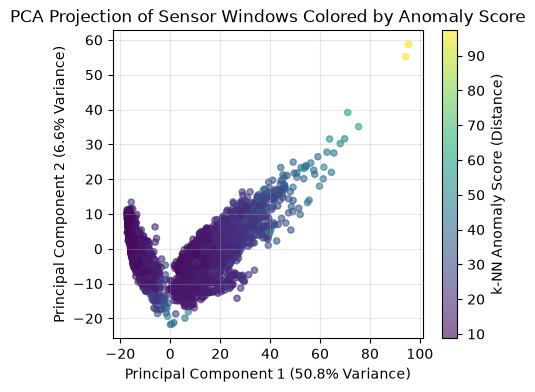

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

# 1. Project high-dimensional X_train_scaled down to 2 dimensions using PCA
pca = PCA(n_components=2, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)

# 2. Create a temporary plotting dataframe
pca_df = pd.DataFrame(X_train_pca, columns=['PC1', 'PC2'])
pca_df['anomaly_score'] = train_anomaly_df['anomaly_score'].values
pca_df['is_anomaly'] = train_anomaly_df['is_anomaly'].values

# 3. Plot the PCA scatter plot
plt.figure(figsize=(5, 4))

# Scatter plot colored by anomaly score
scatter = plt.scatter(
    pca_df['PC1'], 
    pca_df['PC2'], 
    c=pca_df['anomaly_score'], 
    cmap='viridis', 
    alpha=0.6, 
    s=20
)

plt.colorbar(scatter, label='k-NN Anomaly Score (Distance)')
plt.title('PCA Projection of Sensor Windows Colored by Anomaly Score')
plt.xlabel(f'Principal Component 1 ({pca.explained_variance_ratio_[0]*100:.1f}% Variance)')
plt.ylabel(f'Principal Component 2 ({pca.explained_variance_ratio_[1]*100:.1f}% Variance)')
plt.grid(True, alpha=0.3)
plt.show()

In [29]:
print("--- STEP 2: Score Distributions & Thresholding ---")

# Combine training metadata with their anomaly scores
train_anomaly_df = meta_train.copy()
train_anomaly_df['anomaly_score'] = train_anomaly_scores

# Define a threshold (e.g., 95th percentile of the training scores)
threshold = np.percentile(train_anomaly_df['anomaly_score'], 95)
train_anomaly_df['is_anomaly'] = train_anomaly_df['anomaly_score'] > threshold

print(f"Anomaly threshold (95th percentile): {threshold:.4f}")
print(f"Total anomalies flagged in train set: {train_anomaly_df['is_anomaly'].sum()} / {len(train_anomaly_df)}")

--- STEP 2: Score Distributions & Thresholding ---
Anomaly threshold (95th percentile): 22.9177
Total anomalies flagged in train set: 368 / 7352


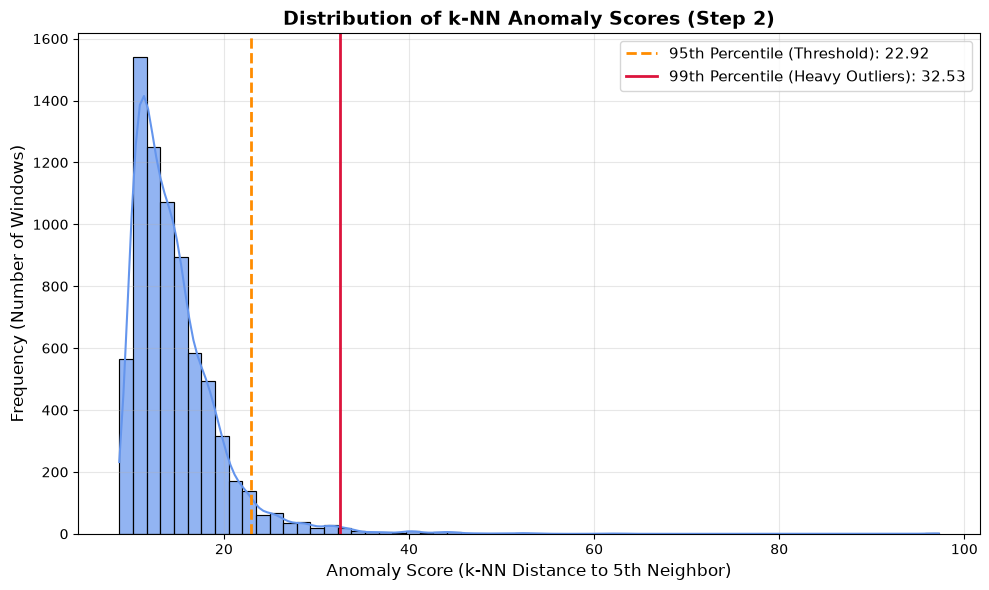

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. Calculate common percentile thresholds (e.g., 95th and 99th)
p95 = np.percentile(train_anomaly_df['anomaly_score'], 95)
p99 = np.percentile(train_anomaly_df['anomaly_score'], 99)

# 2. Plot the distribution histogram and KDE curve
plt.figure(figsize=(10, 6))

sns.histplot(
    train_anomaly_df['anomaly_score'], 
    bins=60, 
    kde=True, 
    color='cornflowerblue', 
    edgecolor='black', 
    alpha=0.7
)

# 3. Draw threshold lines
plt.axvline(p95, color='darkorange', linestyle='--', linewidth=2, label=f'95th Percentile (Threshold): {p95:.2f}')
plt.axvline(p99, color='crimson', linestyle='-', linewidth=2, label=f'99th Percentile (Heavy Outliers): {p99:.2f}')

plt.title('Distribution of k-NN Anomaly Scores (Step 2)', fontsize=14, fontweight='bold')
plt.xlabel('Anomaly Score (k-NN Distance to 5th Neighbor)', fontsize=12)
plt.ylabel('Frequency (Number of Windows)', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [16]:
print("\n--- STEP 3: Anomaly Concentration Analysis ---")

# 3.1 Concentration by Activity (accounting for sample size via mean rate)
activity_summary = train_anomaly_df.groupby('activity_id').agg(
    total_samples=('anomaly_score', 'count'),
    anomaly_count=('is_anomaly', 'sum'),
    anomaly_rate=('is_anomaly', 'mean'),
    mean_score=('anomaly_score', 'mean')
).sort_values(by='anomaly_rate', ascending=False)

print("Anomaly Rate by Activity:")
print(activity_summary)

# 3.2 Concentration by Participant (Subject ID)
participant_summary = train_anomaly_df.groupby('subject_id').agg(
    total_samples=('anomaly_score', 'count'),
    anomaly_count=('is_anomaly', 'sum'),
    anomaly_rate=('is_anomaly', 'mean'),
    mean_score=('anomaly_score', 'mean')
).sort_values(by='anomaly_rate', ascending=False)

print("\nTop Participants by Anomaly Rate:")
print(participant_summary.head())


--- STEP 3: Anomaly Concentration Analysis ---
Anomaly Rate by Activity:
             total_samples  anomaly_count  anomaly_rate  mean_score
activity_id                                                        
3                      986            216      0.219067   19.285711
1                     1226             54      0.044046   14.255383
2                     1073             41      0.038211   14.778665
6                     1407             43      0.030561   12.214474
4                     1286             13      0.010109   11.516947
5                     1374              1      0.000728   11.147948

Top Participants by Anomaly Rate:
            total_samples  anomaly_count  anomaly_rate  mean_score
subject_id                                                        
19                    360             67      0.186111   16.264001
8                     281             45      0.160142   15.660124
23                    372             57      0.153226   15.131813
14          

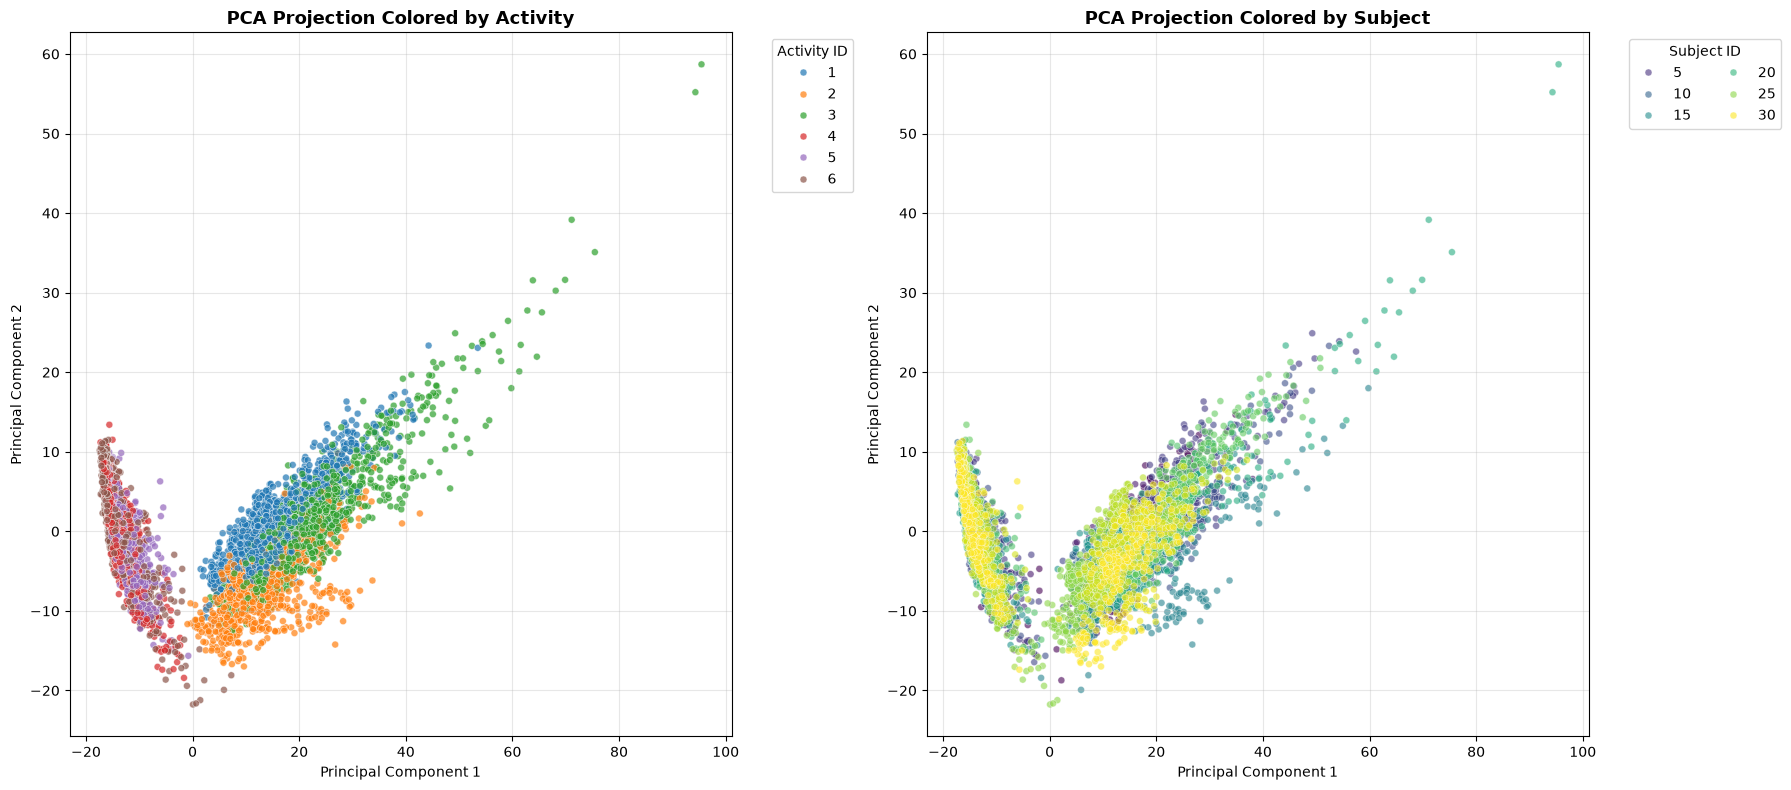

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Ensure train_anomaly_df has the subject_id and activity_id aligned
# (Assuming train_anomaly_df already contains subject_id, activity_id, and is_anomaly)

pca_df['activity_id'] = train_anomaly_df['activity_id'].values
pca_df['subject_id'] = train_anomaly_df['subject_id'].values
pca_df['is_anomaly'] = train_anomaly_df['is_anomaly'].values

# Set up a side-by-side or stacked visualization
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# 1. PCA Plot colored by Activity ID
sns.scatterplot(
    data=pca_df, 
    x='PC1', 
    y='PC2', 
    hue='activity_id', 
    palette='tab10', 
    alpha=0.7, 
    s=25, 
    ax=axes[0]
)
axes[0].set_title('PCA Projection Colored by Activity', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Principal Component 1')
axes[0].set_ylabel('Principal Component 2')
axes[0].legend(title='Activity ID', bbox_to_anchor=(1.05, 1), loc='upper left')
axes[0].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

C:\Users\muhat\AppData\Local\Temp\ipykernel_22740\3602036979.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



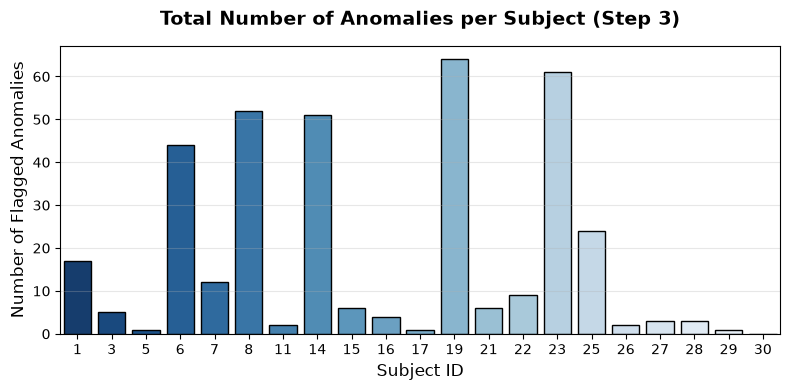

In [44]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Group by subject_id and sum the boolean 'is_anomaly' column to get total counts
subject_anomalies = train_anomaly_df.groupby('subject_id')['is_anomaly'].sum().reset_index()

# 2. Plot the bar chart
plt.figure(figsize=(8, 4))

sns.barplot(
    data=subject_anomalies, 
    x='subject_id', 
    y='is_anomaly', 
    palette='Blues_r', 
    edgecolor='black'
)

plt.title('Total Number of Anomalies per Subject (Step 3)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Subject ID', fontsize=12)
plt.ylabel('Number of Flagged Anomalies', fontsize=12)
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

C:\Users\muhat\AppData\Local\Temp\ipykernel_22740\683396803.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



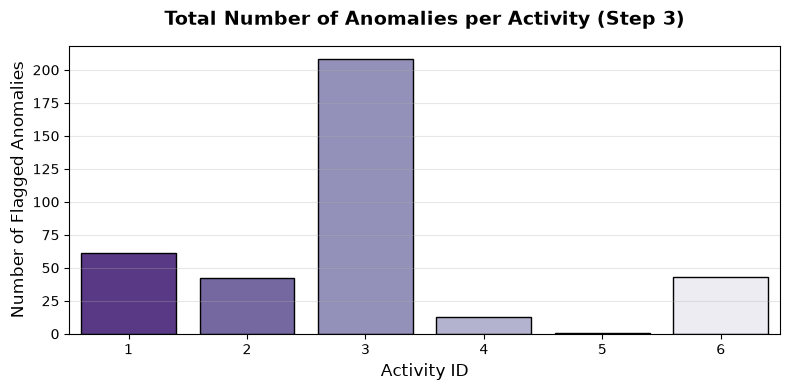

In [43]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Group by activity_id and sum the boolean 'is_anomaly' column to get total counts
activity_anomalies = train_anomaly_df.groupby('activity_id')['is_anomaly'].sum().reset_index()

# Optional: Map numeric activity IDs to descriptive names if you have them, e.g.:
# activity_mapping = {1: 'WALKING', 2: 'WALKING_UPSTAIRS', 3: 'WALKING_DOWNSTAIRS', 4: 'SITTING', 5: 'STANDING', 6: 'LAYING'}
# activity_anomalies['activity_name'] = activity_anomalies['activity_id'].map(activity_mapping)

# 2. Plot the bar chart
plt.figure(figsize=(8, 4))

sns.barplot(
    data=activity_anomalies, 
    x='activity_id', 
    y='is_anomaly', 
    palette='Purples_r', 
    edgecolor='black'
)

plt.title('Total Number of Anomalies per Activity (Step 3)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Activity ID', fontsize=12)
plt.ylabel('Number of Flagged Anomalies', fontsize=12)
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

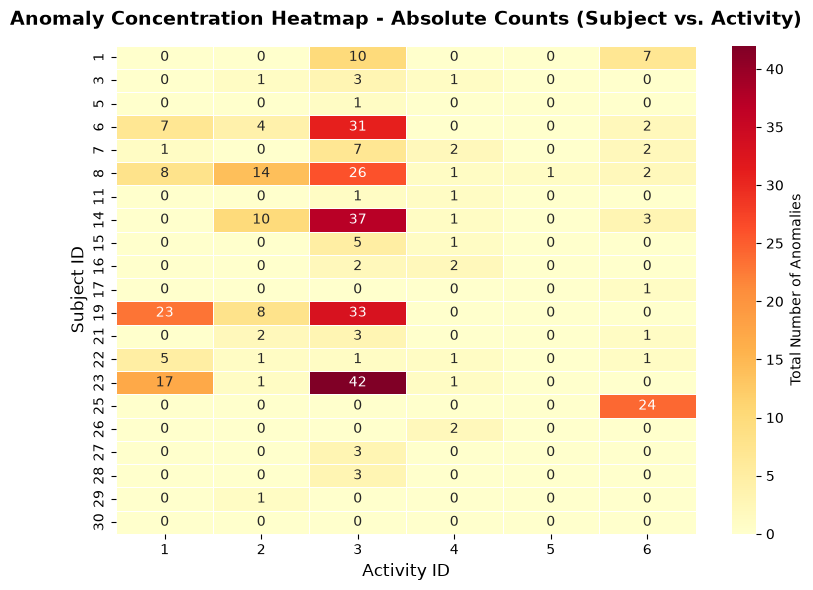

In [50]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Ensure train_anomaly_df has subject_id, activity_id, and is_anomaly
# Calculate absolute count of anomalies grouped by subject and activity using .sum()
concentration_df = train_anomaly_df.groupby(['subject_id', 'activity_id'])['is_anomaly'].sum().reset_index()

# 2. Pivot the table to create a 2D matrix (Subjects x Activities)
heatmap_data = concentration_df.pivot(index='subject_id', columns='activity_id', values='is_anomaly')

# 3. Plot the single heatmap with integer formatting ('d')
plt.figure(figsize=(8, 6))
sns.heatmap(
    heatmap_data, 
    cmap='YlOrRd', 
    annot=True, 
    fmt='d', 
    cbar_kws={'label': 'Total Number of Anomalies'},
    linewidths=0.5
)

plt.title('Anomaly Concentration Heatmap - Absolute Counts (Subject vs. Activity)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Activity ID', fontsize=12)
plt.ylabel('Subject ID', fontsize=12)
plt.tight_layout()
plt.show()

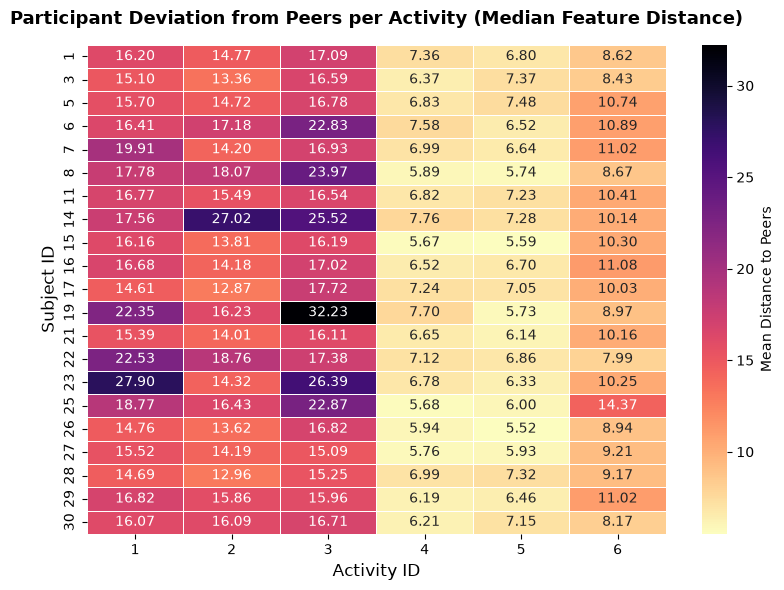

In [56]:
import pandas as pd
import numpy as np
from scipy.spatial.distance import cdist
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Ensure features are in a DataFrame with metadata attached
if isinstance(X_train_scaled, np.ndarray):
    features_df = pd.DataFrame(X_train_scaled, index=train_anomaly_df.index)
else:
    features_df = X_train_scaled.copy()

features_df['subject_id'] = train_anomaly_df['subject_id'].values
features_df['activity_id'] = train_anomaly_df['activity_id'].values

# Identify feature columns (everything except metadata)
feat_cols = [c for c in features_df.columns if c not in ['subject_id', 'activity_id']]

# Step 1: Calculate median feature vector for each participant per activity
median_profiles = features_df.groupby(['activity_id', 'subject_id'])[feat_cols].median().reset_index()

# Step 2: Compare each participant's profile with others performing the same activity
comparison_results = []

for act_id, group in median_profiles.groupby('activity_id'):
    sub_ids = group['subject_id'].values
    vectors = group[feat_cols].values
    
    for i, subj in enumerate(sub_ids):
        target_vector = vectors[i].reshape(1, -1)
        other_vectors = np.delete(vectors, i, axis=0)
        
        # Calculate Euclidean distance to all other subjects' median profiles
        distances = cdist(target_vector, other_vectors, metric='euclidean')[0]
        
        comparison_results.append({
            'activity_id': act_id,
            'subject_id': subj,
            'mean_distance_to_peers': np.mean(distances)
        })

participant_comparison_df = pd.DataFrame(comparison_results)

# Step 3: Pivot into a 2D matrix (Subjects x Activities) for the heatmap
heatmap_data = participant_comparison_df.pivot(index='subject_id', columns='activity_id', values='mean_distance_to_peers')

# Step 4: Plot the heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(
    heatmap_data, 
    cmap='magma_r', 
    annot=True, 
    fmt='.2f', 
    cbar_kws={'label': 'Mean Distance to Peers'},
    linewidths=0.5
)

plt.title('Participant Deviation from Peers per Activity (Median Feature Distance)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Activity ID', fontsize=12)
plt.ylabel('Subject ID', fontsize=12)
plt.tight_layout()
plt.show()

C:\Users\muhat\AppData\Local\Temp\ipykernel_22740\1575524748.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



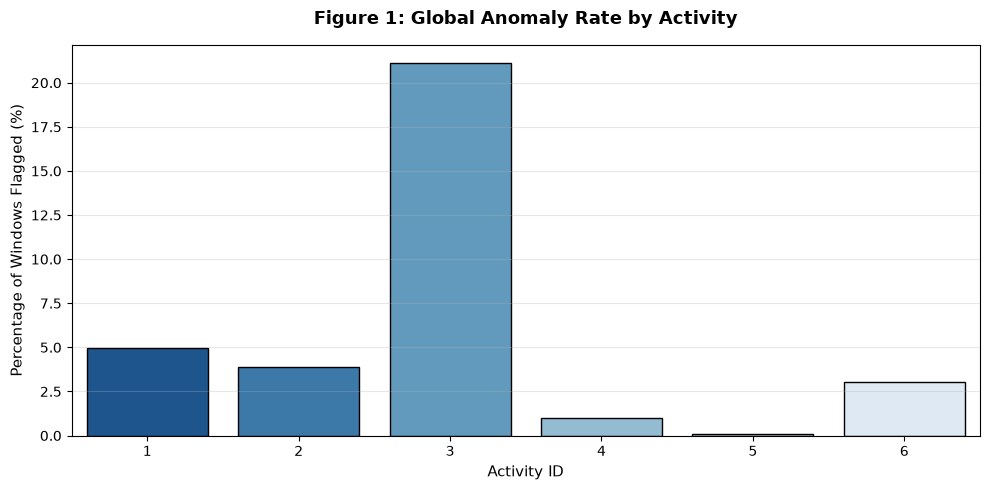

In [57]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Figure 1: Global Anomaly Rate by Activity
act_summary = train_anomaly_df.groupby('activity_id')['is_anomaly'].mean().reset_index()
act_summary['anomaly_percentage'] = act_summary['is_anomaly'] * 100

plt.figure(figsize=(10, 5))
sns.barplot(
    data=act_summary,
    x='activity_id',
    y='anomaly_percentage',
    palette='Blues_r',
    edgecolor='black'
)
plt.title('Figure 1: Global Anomaly Rate by Activity', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Activity ID', fontsize=11)
plt.ylabel('Percentage of Windows Flagged (%)', fontsize=11)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

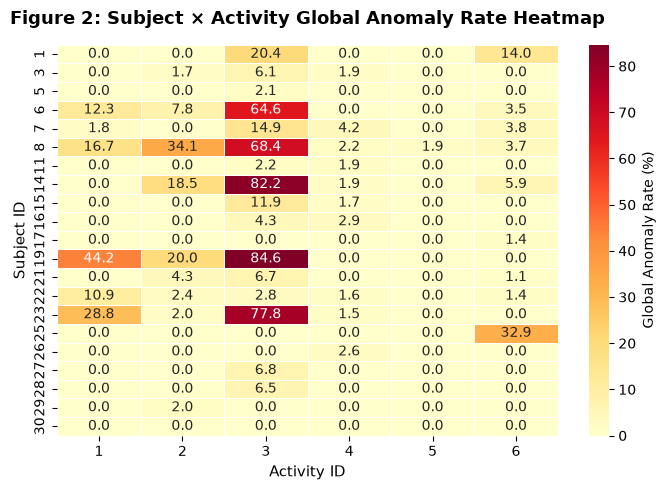

In [60]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Figure 2: Subject × Activity Global Anomaly Rate Heatmap
sub_act_summary = train_anomaly_df.groupby(['subject_id', 'activity_id'])['is_anomaly'].mean().reset_index()
sub_act_summary['anomaly_percentage'] = sub_act_summary['is_anomaly'] * 100

heatmap_data = sub_act_summary.pivot(index='subject_id', columns='activity_id', values='anomaly_percentage')

plt.figure(figsize=(7, 5))
sns.heatmap(
    heatmap_data,
    cmap='YlOrRd',
    annot=True,
    fmt='.1f',
    cbar_kws={'label': 'Global Anomaly Rate (%)'},
    linewidths=0.5
)
plt.title('Figure 2: Subject × Activity Global Anomaly Rate Heatmap', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Activity ID', fontsize=11)
plt.ylabel('Subject ID', fontsize=11)
plt.tight_layout()
plt.show()

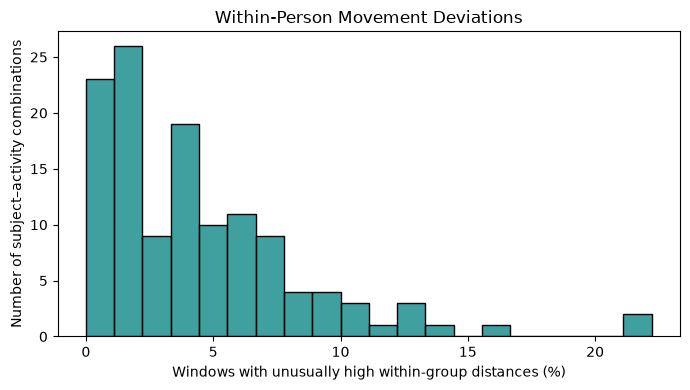

,subject_id,activity_id,n_windows,deviation_rate
35,8,6,54,22.222222
57,16,4,69,21.739130
87,23,4,68,16.176471
41,11,6,57,14.035088
32,8,3,38,13.157895
3,1,4,47,12.765957
22,6,5,57,12.280702
64,17,5,78,11.538462
118,29,5,65,10.769231
2,1,3,49,10.204082


In [62]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

group_cols = ["subject_id", "activity_id"]

# Typical within-group distance
group_median = train_anomaly_df.groupby(group_cols)[
    "local_distance"
].transform("median")

# Median absolute deviation within each group
absolute_deviation = (
    train_anomaly_df["local_distance"] - group_median
).abs()

group_mad = absolute_deviation.groupby(
    [train_anomaly_df[c] for c in group_cols]
).transform("median")

# Robust standardisation within subject-activity combinations
# Near-zero MAD groups are left undefined rather than silently
# treating tiny numerical differences as extreme anomalies.
denominator = 1.4826 * group_mad

train_anomaly_df["local_robust_score"] = (
    (train_anomaly_df["local_distance"] - group_median)
    / denominator.where(denominator > 1e-10)
)

# Illustrative robust threshold, not ground-truth anomaly labels
threshold = 3.5

train_anomaly_df["is_within_group_deviation"] = (
    train_anomaly_df["local_robust_score"] > threshold
)

# Calculate deviation rate for each subject-activity combination
comb_summary = (
    train_anomaly_df
    .groupby(group_cols)
    .agg(
        n_windows=("local_distance", "size"),
        deviation_rate=("is_within_group_deviation", "mean")
    )
    .reset_index()
)

comb_summary["deviation_rate"] *= 100

# Plot
plt.figure(figsize=(7, 4))

sns.histplot(
    comb_summary["deviation_rate"],
    bins=20,
    color="teal",
    edgecolor="black"
)

plt.xlabel("Windows with unusually high within-group distances (%)")
plt.ylabel("Number of subject–activity combinations")
plt.title("Within-Person Movement Deviations")
plt.tight_layout()
plt.show()

display(
    comb_summary.sort_values(
        "deviation_rate", ascending=False
    ).head(10)
)

Our EDA gives us a number of findings in regards to the anomalies in the dataset:
1. Activities are inhenrently more likely to be anomalous. Especially 3 (walking downstairs)
2. People have different gaits and cadences meaning they can be anomalous from the global average
3. A persons movement patterns within an activity can also be anomalous meaning that gate consistency also needs to be evaluated.

## Research Questions

### Research Question 1
**Members**: Atharva & Abrar

**Main Research Question:** Does human movement naturally organise into distinct categories, or into broader families containing overlapping and more specialised movement patterns?

**Methodology:**
1.	Perform unsupervised clustering (e.g., K-Means, GMM) on the 561-feature space.
2.  Analyze the resulting cluster structures (evaluate whether they form distinct groups or hierarchical sub-clusters)
3.  Compare unsupervized cluster assignment directuly against the hierarchical sub-clusters)
4.  Analyze divergence between machine-discovered structures vs human labeled classes

**Sub-Questions & Focus:**

1. Are the clusters truly 6 distinct groups mirroring the activity labels?
2. Can a geometric hierarchy be discovered within the space (e.g., are walking flat and walking upstairs grouped closer together than sitting and standing)?
3. How clearly do static postures separate from dynamic movements?

In [20]:
# Code for Question 1

### Research Question 2
**Members**: Youssef & Sushanth

**Main Research Question:** Are some forms of human movement inherently more variable than others, and does this diversity explain why they appear disproportionately unusual?

**Methodology:**
1.	Execute anomaly detection models (e.g., Isolation Forest, density-based outlier scoring) across the feature space.
2.	Map anomaly and outlier scores directly back against cluster boundaries and feature variance metrics.
3.	Analyze whether anomaly concentrations are isolated to specific activities or driven by high-variance physical regimes.

**Questions and Focus:**
1. Are high-intensity or dynamic activities (like walking downstairs) inherently more variable, causing them to trigger false anomaly flags?
2. Are anomalies uniformly distributed across all activities, or clustered heavily in specific movement transitions?
3. Do unusual scores reflect true physical irregularities or geometric boundary crowding?


In [21]:
# Code for Question 2

### Research Question 3
**Members**: Muhatasim & Subhashini

**Main Research Question:** Do unusual movement observations represent consistent differences in how individuals move, or isolated departures from otherwise typical movement behaviour?

**Methodology:**
1.	Take the cluster assignments and anomaly shortlists generated in RQ1 and RQ2.
2.	Cross-tabulate these spatial outputs against the known subject ID metadata (the 30 participants).
3.	Evaluate whether outlier concentrations are driven by single individuals or shared across multiple subjects.
4.	Investigate how individual biometric walking styles interact with global unsupervised boundaries (leveraging the sequential nature of data per subject).

**Sub-questions and focus:**
1. Are the top anomalies dominated by a single eccentric participant (e.g., one subject's unique stride), or are they common instances experienced across many people?
2. Does the unsupervised space fracture by participant identity rather than activity class?
3. How does unmanaged inter-subject variance distort global anomaly detection?


In [22]:
# Code for Question 3